In [1]:
import tifffile as tiff
import os

In [2]:
from labmate.acquisition_notebook import AcquisitionAnalysisManager

In [3]:
import numpy as np

In [4]:
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

# Loading data

**Select folder**  

In [5]:
data_folder = r"./data/thorcam/"
# acquisition_folder = r"260914_110115_782" # shg tons of modes
acquisition_folder = r"260918_151907_483"

full_path =os.path.join(data_folder, acquisition_folder)
print(os.listdir(full_path))

['0001-20260918_151908_322.tif', 'Experiment.json']


**Open file**

In [6]:
capture_path = os.path.join(full_path, '0001-20260918_151908_322.tif')
capture = tiff.imread(capture_path)
print(capture.shape)
print(capture.dtype)

(132, 1080, 1440, 3)
uint16


**Display one frame**

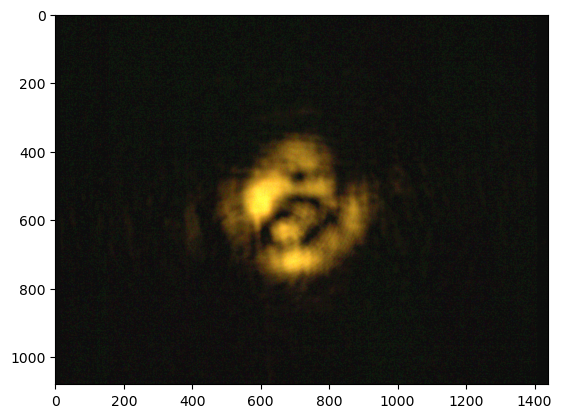

In [7]:
plt.imshow(capture[100], cmap="Greys")
# plt.colorbar()
plt.show()

# Finding relevent frames

**Generate a copy**

In [8]:
capture_normalized = np.round(capture / 1023 * 255).astype(np.uint8)

print("Normalized shape:", capture_normalized.shape)
print("Normalized type:", capture_normalized.dtype)
print("Normalized range:", capture_normalized.min(), capture_normalized.max())

Normalized shape: (132, 1080, 1440, 3)
Normalized type: uint8
Normalized range: 0 255


**Look at the frames as a movie**

In [9]:
plt.rcParams["animation.embed_limit"] = 200  # MB

In [10]:
fig, ax = plt.subplots()

im = ax.imshow(capture_normalized[0], cmap="gray")
ax.axis("off")

# Frame counter
text = ax.text(
    0.02, 0.95,
    "",
    transform=ax.transAxes,
    color="white",
    fontsize=12,
    verticalalignment="top",
    bbox=dict(facecolor="black", alpha=0.6)
)

def update(i):
    im.set_data(capture_normalized[i])
    text.set_text(f"Frame: {i}")
    return im, text

ani = FuncAnimation(
    fig,
    update,
    frames=len(capture_normalized),
    interval=30,
    blit=True
)

plt.close(fig)

HTML(ani.to_jshtml())

**Select frames**

Manual selection

In [11]:
# frame_indices = [12, 43, 65, 94, 123] # TEM00 ?
# frame_indices = [30, 99, 114, 125] # high order mode
# frame_indices = [20, 53, 68, 108, 120, 130, 133] # other

n = 1
frame_indices = [i for i in range(0, capture_normalized.shape[0], n)]  # every n-th frame

Automatically select non black frames

In [18]:
# Convert RGB image to brightness
brightness = capture_normalized.mean(axis=3)

# Mean brightness of each frame
frame_brightness = brightness.mean(axis=(1, 2))

# Adjust this threshold if necessary
threshold = 6

frame_indices = np.where(frame_brightness > threshold)[0]

print("Number of non-black frames:", len(frame_indices))
print("Frame indices:")
print(frame_indices)

Number of non-black frames: 57
Frame indices:
[ 17  18  19  20  21  22  23  24  26  27  40  41  42  43  44  45  46  47
  48  49  50  51  52  54  55  56  57  58  60  61  62  63  77  78  79  81
  82  83  84  85  86  87  88  89 102 105 106 109 110 112 113 114 115 127
 128 130 131]


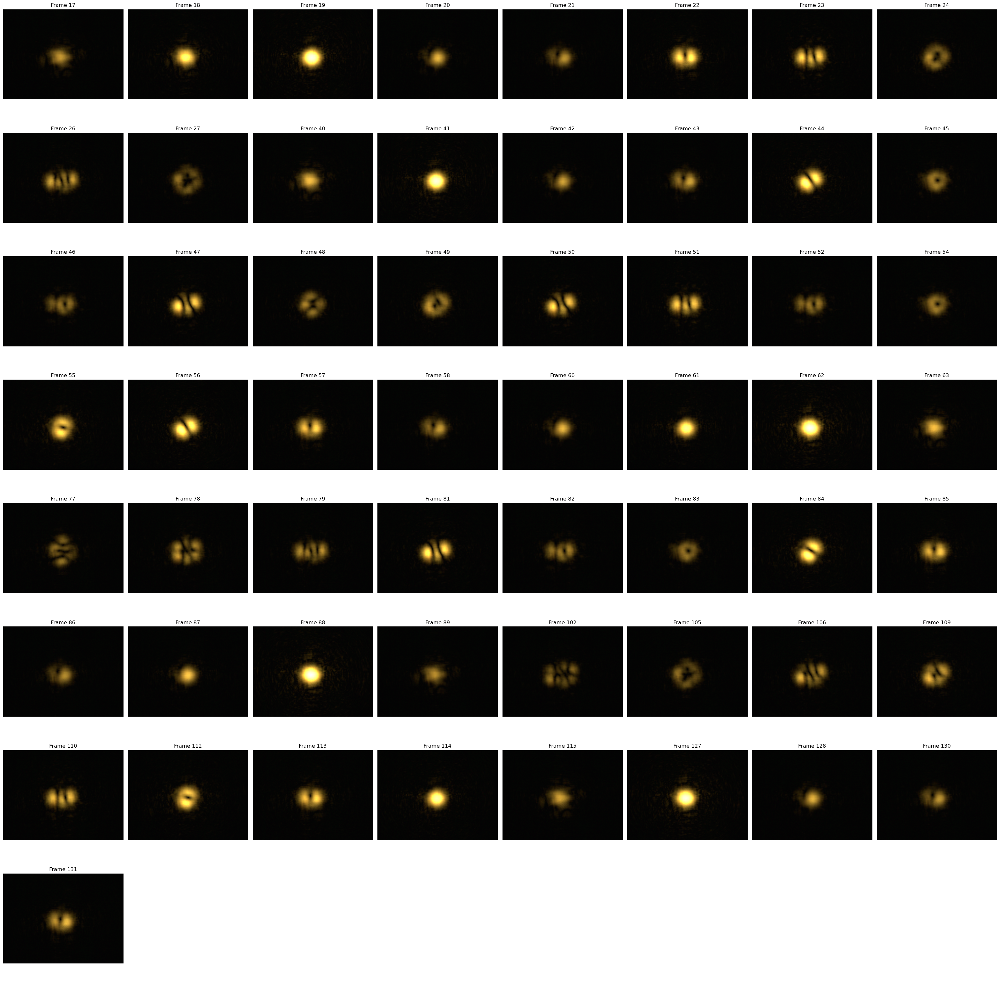

In [19]:
n = len(frame_indices)

ngrid = int(np.ceil(np.sqrt(n)))

fig, axes = plt.subplots(
    ngrid,
    ngrid,
    figsize=(4 * ngrid, 4 * ngrid)
)

axes = np.array(axes).reshape(-1)

for ax, i in zip(axes, frame_indices):
    ax.imshow(capture_normalized[i])
    ax.set_title(f"Frame {i}")
    ax.axis("off")

# Hide unused panels
for ax in axes[len(frame_indices):]:
    ax.axis("off")

plt.tight_layout()
plt.show()